In [26]:
import pandas as pd
import sqlite3 as sq
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import fiona
import os
import io
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.functions import read_census_table, read_wp23_table

Read in base year from the Woods and Poole 2023 Vintage Database. The dependencies for these have been run, and the data is written out in the file "Employment Full Treatment.ipynb, found in the repository Woods-and-Poole-2023.

In [27]:
wp = read_wp23_table('EmploymentBaseYear')

In [28]:
thelist = ['Christian County, Kentucky', 'Trigg County, Kentucky', 'Stewart County, Tennessee', 'Montgomery County, Tennessee']
wp_filtered = wp.loc[wp['NAME'].isin(thelist)].reset_index(drop = True)

In [29]:
wp_filtered.head()

,NAME,Education,Food Services,Government,Industrial,Medical,Office,Other,Retail,Service,Total employment (number of jobs)
0,"Christian County, Kentucky",657.0,2691.0,35865.0,10131.0,4313.0,7925.0,3140.0,4047.0,2725.0,71494.428571
1,"Montgomery County, Tennessee",3172.0,9784.0,9125.0,14732.0,10780.0,20778.0,7515.0,12400.0,8648.0,96933.785714
2,"Stewart County, Tennessee",44.0,291.0,986.0,830.0,224.0,644.0,1110.0,470.0,402.0,4998.357143
3,"Trigg County, Kentucky",54.0,417.0,704.0,604.0,557.0,1030.0,910.0,591.0,379.0,5247.678571


In [30]:
ind_dict = {'Education': 'EMP_EDUCATION', 'Food Services': 'EMP_FOODSERVICE', 'Government': 'EMP_GOVERNMENT', 'Industrial': 'EMP_INDUSTRIAL', 
'Medical': 'EMP_MEDICAL', 'Office': 'EMP_OFFICE', 'Retail': 'EMP_RETAIL', 'Service': 'EMP_SERVICE', 'Total employment (number of jobs)': 'EMP', 'Other': 'EMP_OTHER'}
wp_filtered = wp_filtered.rename(columns = ind_dict)

Now we're going to distribute this based on the same LEHD distribution of place of work employment by block for total jobs, with the most accurate representation of 2023, coming from the 2023 LODES 8 documents for S000 (all demographics), JT00 (all jobs). Here's the filestructure: https://lehd.ces.census.gov/data/lodes/LODES8/LODESTechDoc8.4.pdf

In [31]:
kylodes = pd.read_csv(r"https://lehd.ces.census.gov/data/lodes/LODES8/ky/wac/ky_wac_S000_JT00_2023.csv.gz")
tnlodes = pd.read_csv(r"https://lehd.ces.census.gov/data/lodes/LODES8/tn/wac/tn_wac_S000_JT00_2023.csv.gz")

In [32]:
tnlodes.head(1)

,w_geocode,C000,CA01,CA02,CA03,CE01,CE02,CE03,CNS01,CNS02,...,CFA02,CFA03,CFA04,CFA05,CFS01,CFS02,CFS03,CFS04,CFS05,createdate
0,470010201001000,162,60,71,31,44,75,43,0,0,...,0,0,0,0,0,0,0,0,0,20251202


In [33]:
lodes = pd.concat([kylodes, tnlodes])

In [34]:
coldict = {'CNS01': '11 (Agriculture, Forestry, Fishing and Hunting)', 'CNS02': '21 (Mining, Quarrying, and Oil and Gas Extraction)', 
'CNS03': '22 (Utilities)', 'CNS04': '23 (Construction)', 'CNS05': '31-33 (Manufacturing)', 'CNS06': '42 (Wholesale Trade)', 
'CNS07': '44-45 (Retail Trade)', 'CNS08': '48-49 (Transportation and Warehousing)', 'CNS09': '51 (Information)', 
'CNS10': '52 (Finance and Insurance)', 'CNS11': '53 (Real Estate and Rental and Leasing)', 'CNS12': '54 (Professional, Scientific, and Technical Services)', 
'CNS13': '55 (Management of Companies and Enterprises)', 'CNS14': '56 (Administrative and Support and Waste Management and Remediation Services)', 'CNS15': '61 (Educational Services)', 
'CNS16': '62 (Health Care and Social Assistance)', 'CNS17': '71 (Arts, Entertainment, and Recreation)', 'CNS18': '72 (Accommodation and Food Services)', 
'CNS19': '81 (Other Services [except Public Administration])', 'CNS20': '92 (Public Administration)', 'C000': 'Total employment (number of jobs)'}

lodes = lodes.rename(columns = coldict)

In [35]:
# lodes_transp = lodes[['w_geocode', 'Total employment (number of jobs)', '11 (Agriculture, Forestry, Fishing and Hunting)',  '21 (Mining, Quarrying, and Oil and Gas Extraction)', 
# '22 (Utilities)', '23 (Construction)', '31-33 (Manufacturing)', '42 (Wholesale Trade)', '44-45 (Retail Trade)', '48-49 (Transportation and Warehousing)', 
# '51 (Information)', '52 (Finance and Insurance)', '53 (Real Estate and Rental and Leasing)', '54 (Professional, Scientific, and Technical Services)', 
# '55 (Management of Companies and Enterprises)', '56 (Administrative and Support and Waste Management and Remediation Services)', 
# '61 (Educational Services)', '62 (Health Care and Social Assistance)', '71 (Arts, Entertainment, and Recreation)', 
# '72 (Accommodation and Food Services)', '81 (Other Services [except Public Administration])', '92 (Public Administration)']].set_index('w_geocode').transpose()

In [36]:
lodes_filt = lodes[['w_geocode', 'Total employment (number of jobs)', '11 (Agriculture, Forestry, Fishing and Hunting)',  '21 (Mining, Quarrying, and Oil and Gas Extraction)', 
'22 (Utilities)', '23 (Construction)', '31-33 (Manufacturing)', '42 (Wholesale Trade)', '44-45 (Retail Trade)', '48-49 (Transportation and Warehousing)', 
'51 (Information)', '52 (Finance and Insurance)', '53 (Real Estate and Rental and Leasing)', '54 (Professional, Scientific, and Technical Services)', 
'55 (Management of Companies and Enterprises)', '56 (Administrative and Support and Waste Management and Remediation Services)', 
'61 (Educational Services)', '62 (Health Care and Social Assistance)', '71 (Arts, Entertainment, and Recreation)', 
'72 (Accommodation and Food Services)', '81 (Other Services [except Public Administration])', '92 (Public Administration)']]

In [37]:
lodes_filt.head(2)

,w_geocode,Total employment (number of jobs),"11 (Agriculture, Forestry, Fishing and Hunting)","21 (Mining, Quarrying, and Oil and Gas Extraction)",22 (Utilities),23 (Construction),31-33 (Manufacturing),42 (Wholesale Trade),44-45 (Retail Trade),48-49 (Transportation and Warehousing),...,53 (Real Estate and Rental and Leasing),"54 (Professional, Scientific, and Technical Services)",55 (Management of Companies and Enterprises),56 (Administrative and Support and Waste Management and Remediation Services),61 (Educational Services),62 (Health Care and Social Assistance),"71 (Arts, Entertainment, and Recreation)",72 (Accommodation and Food Services),81 (Other Services [except Public Administration]),92 (Public Administration)
0,210019701001004,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,210019701001018,3,0,0,0,0,0,0,3,0,...,0,0,0,0,0,0,0,0,0,0


In [38]:
#this is based on the aggregation given to me by MS during development of the base year for UrbanSIM model update
industry_mapping = {
    "11 (Agriculture, Forestry, Fishing and Hunting)": "EMP_OTHER",
    "21 (Mining, Quarrying, and Oil and Gas Extraction)": "EMP_OTHER",
    "22 (Utilities)": "EMP_INDUSTRIAL",
    "23 (Construction)": "EMP_OTHER",
    "31-33 (Manufacturing)": "EMP_INDUSTRIAL",
    "42 (Wholesale Trade)": "EMP_INDUSTRIAL",
    "44-45 (Retail Trade)": "EMP_RETAIL",
    "48-49 (Transportation and Warehousing)": "EMP_INDUSTRIAL",
    "51 (Information)": "EMP_OFFICE",
    "52 (Finance and Insurance)": "EMP_OFFICE",
    "53 (Real Estate and Rental and Leasing)": "EMP_OFFICE",
    "54 (Professional, Scientific, and Technical Services)": "EMP_OFFICE",
    "55 (Management of Companies and Enterprises)": "EMP_OFFICE",
    "56 (Administrative and Support and Waste Management and Remediation Services)": "EMP_SERVICE",
    "61 (Educational Services)": "EMP_EDUCATION",
    "62 (Health Care and Social Assistance)": "EMP_MEDICAL",
    "71 (Arts, Entertainment, and Recreation)": "EMP_SERVICE",
    "72 (Accommodation and Food Services)": "EMP_FOODSERVICE",
    "81 (Other Services [except Public Administration])": "EMP_SERVICE",
    "92 (Public Administration)": "EMP_GOVERNMENT", 
    "Total employment (number of jobs)": "EMP"
}

In [39]:
lodes_grouped = (lodes_filt.rename(columns=industry_mapping).T.groupby(level=0).sum().T)

In [40]:
lodes_grouped.head(2)

,EMP,EMP_EDUCATION,EMP_FOODSERVICE,EMP_GOVERNMENT,EMP_INDUSTRIAL,EMP_MEDICAL,EMP_OFFICE,EMP_OTHER,EMP_RETAIL,EMP_SERVICE,w_geocode
0,1,0,0,0,0,0,0,1,0,0,210019701001004
1,3,0,0,0,0,0,0,0,3,0,210019701001018


In [41]:
county_map = {'21047': 'Christian County, Kentucky','21221': 'Trigg County, Kentucky', '47161': 'Stewart County, Tennessee', '47125': 'Montgomery County, Tennessee'}

lodes_grouped['COUNTY'] = lodes_grouped['w_geocode'].astype(str).str[:5].map(county_map)
lodes_grouped['COUNTYFP'] = lodes_grouped['w_geocode'].astype(str).str[:5]
lodes_grouped = lodes_grouped.rename(columns = {'w_geocode': 'GEO_ID'})

#drop rows that don't match either county
lodes_grouped = lodes_grouped.dropna(subset=['COUNTY']).reset_index(drop=True)

In [42]:
lodes_grouped.head(2)

,EMP,EMP_EDUCATION,EMP_FOODSERVICE,EMP_GOVERNMENT,EMP_INDUSTRIAL,EMP_MEDICAL,EMP_OFFICE,EMP_OTHER,EMP_RETAIL,EMP_SERVICE,GEO_ID,COUNTY,COUNTYFP
0,20,0,0,0,20,0,0,0,0,0,210472001001001,"Christian County, Kentucky",21047
1,3,0,0,0,3,0,0,0,0,0,210472001001005,"Christian County, Kentucky",21047


In [43]:
wp_filtered.head(2)

,NAME,EMP_EDUCATION,EMP_FOODSERVICE,EMP_GOVERNMENT,EMP_INDUSTRIAL,EMP_MEDICAL,EMP_OFFICE,EMP_OTHER,EMP_RETAIL,EMP_SERVICE,EMP
0,"Christian County, Kentucky",657.0,2691.0,35865.0,10131.0,4313.0,7925.0,3140.0,4047.0,2725.0,71494.428571
1,"Montgomery County, Tennessee",3172.0,9784.0,9125.0,14732.0,10780.0,20778.0,7515.0,12400.0,8648.0,96933.785714


In [44]:
#split controls
trigg_control = wp_filtered.loc[wp_filtered['NAME'] == 'Trigg County, Kentucky']
christian_control = wp_filtered.loc[wp_filtered['NAME'] == 'Christian County, Kentucky']
stewart_control = wp_filtered.loc[wp_filtered['NAME'] == 'Stewart County, Tennessee']
montgomery_control = wp_filtered.loc[wp_filtered['NAME'] == 'Montgomery County, Tennessee']

#split blocks
trigg_blk = lodes_grouped.loc[lodes_grouped['COUNTY'] == 'Trigg County, Kentucky']
christian_blk = lodes_grouped.loc[lodes_grouped['COUNTY'] == 'Christian County, Kentucky']
stewart_blk = lodes_grouped.loc[lodes_grouped['COUNTY'] == 'Stewart County, Tennessee']
montgomery_blk = lodes_grouped.loc[lodes_grouped['COUNTY'] == 'Montgomery County, Tennessee']

In [45]:
test = stewart_blk.copy()
test['Summer'] = 1
print("This is the number of blocks in Stewart County with employment: " + str(test['Summer'].sum()))

This is the number of blocks in Stewart County with employment: 92


In [46]:
#list of categories
emp_cats = ['EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT', 'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE', 'EMP_RETAIL', 'EMP_SERVICE', 'EMP_OTHER']
#list including all employment
allemp_cols = ['EMP', 'EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT', 'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE', 'EMP_RETAIL', 'EMP_SERVICE', 'EMP_OTHER']

In [47]:
# #make sure no zeros even when split by county
# county_blks = ['trigg', 'christian', 'stewart', 'montgomery']

# for county in county_blks:
#     column_sums = globals()[f'{county}_blk'][emp_cols].sum()
#     print(f'\n{county.title()} County')
#     print(column_sums)

In [48]:
# Employment categories
emp_cols = [
    'EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT',
    'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE',
    'EMP_RETAIL', 'EMP_SERVICE', 'EMP_OTHER'
]

# County dataframes
counties = {
    'trigg': {
        'blocks': trigg_blk,
        'control': trigg_control
    },
    'christian': {
        'blocks': christian_blk,
        'control': christian_control
    },
    'stewart': {
        'blocks': stewart_blk,
        'control': stewart_control
    },
    'montgomery': {
        'blocks': montgomery_blk,
        'control': montgomery_control
    }
}

# Round allocations while preserving totals
def controlled_round(values, target):
    values = np.asarray(values, dtype=float)

    base = np.floor(values).astype(int)
    remainder = int(target - base.sum())

    if remainder < 0 or remainder > len(values):
        raise ValueError("Rounding target is incompatible with allocations")

    order = np.argsort(-(values - base), kind='stable')
    base[order[:remainder]] += 1

    return base


# Store outputs
allocations = {}
comparisons = {}

# --------------------------------------------------
# ALLOCATE EMPLOYMENT BY COUNTY
# --------------------------------------------------

for county, dfs in counties.items():

    print(f'\nProcessing {county.title()} County')

    blk = dfs['blocks']
    control = dfs['control']

    alloc = blk.copy()

    # Preserve county employment category controls
    county_categories = control[emp_cols].iloc[0].to_numpy(dtype=float)
    col_targets = np.rint(county_categories).astype(int)

    # Allocate each category independently
    for col, target in zip(emp_cols, col_targets):

        # Block-level LODES employment for this category
        block_values = blk[col].to_numpy(dtype=float)

        # Calculate geographic shares
        allocation = block_values / block_values.sum()

        # Apply Woods & Poole county control
        allocated_values = allocation * target

        # Round while preserving county category total
        alloc[col] = controlled_round(allocated_values, target)

    # Calculate total employment from allocated categories
    alloc['EMP'] = alloc[emp_cols].sum(axis=1)

    # --------------------------------------------------
    # QUALITY CONTROL
    # --------------------------------------------------

    # Verify county category controls
    assert np.array_equal(
        alloc[emp_cols].sum().to_numpy(),
        col_targets
    ), f"{county}: County category controls do not reconcile"

    # Verify block EMP equals sum of categories
    assert (
        alloc[emp_cols].sum(axis=1) == alloc['EMP']
    ).all(), f"{county}: Block employment totals do not reconcile"

    # Verify no negative employment values
    assert (alloc[emp_cols + ['EMP']] >= 0).all().all()

    # Verify whole-number jobs
    assert np.array_equal(
        alloc[emp_cols + ['EMP']].to_numpy(),
        alloc[emp_cols + ['EMP']].to_numpy(dtype=int)
    )

    # Compare allocated totals to county controls
    comparison = pd.DataFrame({
        'County Control': col_targets,
        'Allocated Total': alloc[emp_cols].sum().to_numpy()
    }, index=emp_cols)

    comparison['Difference'] = (
        comparison['Allocated Total'] - comparison['County Control']
    )

    allocations[county] = alloc
    comparisons[county] = comparison

    print(f'{county.title()} County allocation validated!')


# --------------------------------------------------
# FINAL OUTPUTS
# --------------------------------------------------

trigg_alloc = allocations['trigg']
christian_alloc = allocations['christian']
stewart_alloc = allocations['stewart']
montgomery_alloc = allocations['montgomery']

combined_alloc = pd.concat(
    allocations.values(),
    ignore_index=True
)

print('\nAll counties processed successfully!')


Processing Trigg County
Trigg County allocation validated!

Processing Christian County
Christian County allocation validated!

Processing Stewart County
Stewart County allocation validated!

Processing Montgomery County
Montgomery County allocation validated!

All counties processed successfully!


In [49]:
# blk = stewart_blk
# control = stewart_control

# print("Block EMP total:", blk['EMP'].sum())
# print("Sum of block categories:", blk[emp_cols].sum().sum())
# print("County category control:", control[emp_cols].sum(axis=1).iloc[0])

# print("\nBlocks with EMP = 0:", (blk['EMP'] == 0).sum())
# print("Blocks with categories = 0:", (blk[emp_cols].sum(axis=1) == 0).sum())

# print("\nCategory comparison:")
# display(pd.DataFrame({
#     'Block Total': blk[emp_cols].sum(),
#     'County Control': control[emp_cols].iloc[0]
# }))

A lil' QA

In [50]:
emp_cols = ['EMP', 'EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT', 'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE', 'EMP_OTHER', 'EMP_RETAIL', 'EMP_SERVICE']

In [51]:
print("THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR CHRISTIAN COUNTY")

comparison = pd.DataFrame({'County Control': christian_control[emp_cols].iloc[0], 'Allocated Total': christian_alloc[emp_cols].sum()})

comparison['Difference'] = (comparison['Allocated Total'] - comparison['County Control'])

print(comparison)


THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR CHRISTIAN COUNTY
                 County Control  Allocated Total  Difference
EMP                71494.428571            71494   -0.428571
EMP_EDUCATION        657.000000              657    0.000000
EMP_FOODSERVICE     2691.000000             2691    0.000000
EMP_GOVERNMENT     35865.000000            35865    0.000000
EMP_INDUSTRIAL     10131.000000            10131    0.000000
EMP_MEDICAL         4313.000000             4313    0.000000
EMP_OFFICE          7925.000000             7925    0.000000
EMP_OTHER           3140.000000             3140    0.000000
EMP_RETAIL          4047.000000             4047    0.000000
EMP_SERVICE         2725.000000             2725    0.000000


In [52]:
print("THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR TRIGG COUNTY")

comparison = pd.DataFrame({'County Control': trigg_control[emp_cols].iloc[0], 'Allocated Total': trigg_alloc[emp_cols].sum()})

comparison['Difference'] = (comparison['Allocated Total'] - comparison['County Control'])

print(comparison)

THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR TRIGG COUNTY
                 County Control  Allocated Total  Difference
EMP                 5247.678571             5246   -1.678571
EMP_EDUCATION         54.000000               54    0.000000
EMP_FOODSERVICE      417.000000              417    0.000000
EMP_GOVERNMENT       704.000000              704    0.000000
EMP_INDUSTRIAL       604.000000              604    0.000000
EMP_MEDICAL          557.000000              557    0.000000
EMP_OFFICE          1030.000000             1030    0.000000
EMP_OTHER            910.000000              910    0.000000
EMP_RETAIL           591.000000              591    0.000000
EMP_SERVICE          379.000000              379    0.000000


In [53]:
print("THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR STEWART COUNTY")

comparison = pd.DataFrame({'County Control': stewart_control[emp_cols].iloc[0], 'Allocated Total': stewart_alloc[emp_cols].sum()})

comparison['Difference'] = (comparison['Allocated Total'] - comparison['County Control'])

print(comparison)

THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR STEWART COUNTY
                 County Control  Allocated Total  Difference
EMP                 4998.357143             5001    2.642857
EMP_EDUCATION         44.000000               44    0.000000
EMP_FOODSERVICE      291.000000              291    0.000000
EMP_GOVERNMENT       986.000000              986    0.000000
EMP_INDUSTRIAL       830.000000              830    0.000000
EMP_MEDICAL          224.000000              224    0.000000
EMP_OFFICE           644.000000              644    0.000000
EMP_OTHER           1110.000000             1110    0.000000
EMP_RETAIL           470.000000              470    0.000000
EMP_SERVICE          402.000000              402    0.000000


In [54]:
print("THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR MONTGOMERY COUNTY")

comparison = pd.DataFrame({'County Control': montgomery_control[emp_cols].iloc[0], 'Allocated Total': montgomery_alloc[emp_cols].sum()})

comparison['Difference'] = (comparison['Allocated Total'] - comparison['County Control'])

print(comparison)

THIS TABLE COMPARES THE ALLOCATED SUM TO THE COUNTY CONTROL FOR MONTGOMERY COUNTY
                 County Control  Allocated Total  Difference
EMP                96933.785714            96934    0.214286
EMP_EDUCATION       3172.000000             3172    0.000000
EMP_FOODSERVICE     9784.000000             9784    0.000000
EMP_GOVERNMENT      9125.000000             9125    0.000000
EMP_INDUSTRIAL     14732.000000            14732    0.000000
EMP_MEDICAL        10780.000000            10780    0.000000
EMP_OFFICE         20778.000000            20778    0.000000
EMP_OTHER           7515.000000             7515    0.000000
EMP_RETAIL         12400.000000            12400    0.000000
EMP_SERVICE         8648.000000             8648    0.000000


In [55]:
#remove total employment from the list
emp_cols.remove('EMP')

#go through emp_cols along axis=1 (operate across rows) - and produce a sum, then subtract the total employment from this to get the difference
#assign creates a new column and returns a new dataframe
qc = combined_alloc.assign(Difference=combined_alloc[emp_cols].sum(axis=1) - combined_alloc['EMP'])

#group these differences by county and create new columns blocks, # of non null differences, minimum difference, maximum difference, sum of all block level differences
summary = qc.groupby('COUNTY')['Difference'].agg(Blocks='count', Min='min', Max='max', Total_Difference='sum', 
#custom lambda function: # of blocks where categories don't equal EMP (booleans function as 1/0 when operated on)
Blocks_Mismatched=lambda x: (x != 0).sum(),
#custom lambda function: # of blocks that reconcile exactly
Percent_Matched=lambda x: (x == 0).mean() * 100)

#display results
print("EMPLOYMENT ALLOCATION QUALITY CONTROL")
print("This table summarizes whether the sum of employment categories")
print("equals total employment (EMP) for each Census block, by county.")
print("A successful allocation has zero mismatched blocks and 100% matched.")
print(summary)

EMPLOYMENT ALLOCATION QUALITY CONTROL
This table summarizes whether the sum of employment categories
equals total employment (EMP) for each Census block, by county.
A successful allocation has zero mismatched blocks and 100% matched.
                              Blocks  Min  Max  Total_Difference  \
COUNTY                                                             
Christian County, Kentucky       575    0    0                 0   
Montgomery County, Tennessee     841    0    0                 0   
Stewart County, Tennessee         92    0    0                 0   
Trigg County, Kentucky           127    0    0                 0   

                              Blocks_Mismatched  Percent_Matched  
COUNTY                                                            
Christian County, Kentucky                    0            100.0  
Montgomery County, Tennessee                  0            100.0  
Stewart County, Tennessee                     0            100.0  
Trigg County, Kentucky

In [56]:
tn_alloc = combined_alloc.loc[combined_alloc['COUNTY'].str.contains('Tennessee')]
tn_alloc['GEO_ID'] = tn_alloc['GEO_ID'].astype(str)
ky_alloc = combined_alloc.loc[combined_alloc['COUNTY'].str.contains('Kentucky')]
ky_alloc['GEO_ID'] = ky_alloc['GEO_ID'].astype(str)

In [ ]:
tn = gpd.read_file("https://www2.census.gov/geo/tiger/TIGER2024/TABBLOCK20/tl_2024_47_tabblock20.zip")
ky = gpd.read_file("https://www2.census.gov/geo/tiger/TIGER2024/TABBLOCK20/tl_2024_21_tabblock20.zip")


In [88]:
tnlist = {'161', '125'}
kylist = {'047', '221'}
tn_filt = tn.loc[tn['COUNTYFP20'].isin(tnlist)]
ky_filt = ky.loc[ky['COUNTYFP20'].isin(kylist)]
tnbks = tn_filt[['GEOID20', 'geometry']].rename(columns = {'GEOID20': 'GEO_ID'})
kybks = ky_filt[['GEOID20', 'geometry']].rename(columns = {'GEOID20': 'GEO_ID'})
tnbks['GEO_ID'] = tnbks['GEO_ID'].astype(str)
kybks['GEO_ID'] = kybks['GEO_ID'].astype(str)

In [89]:
ky_join = ky_alloc.merge(kybks, on = 'GEO_ID', how = 'inner')
tn_join = tn_alloc.merge(tnbks, on = 'GEO_ID', how = 'inner')

In [90]:
ky_join.info()

<class 'pandas.DataFrame'>
RangeIndex: 702 entries, 0 to 701
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   EMP              702 non-null    int64   
 1   EMP_EDUCATION    702 non-null    int64   
 2   EMP_FOODSERVICE  702 non-null    int64   
 3   EMP_GOVERNMENT   702 non-null    int64   
 4   EMP_INDUSTRIAL   702 non-null    int64   
 5   EMP_MEDICAL      702 non-null    int64   
 6   EMP_OFFICE       702 non-null    int64   
 7   EMP_OTHER        702 non-null    int64   
 8   EMP_RETAIL       702 non-null    int64   
 9   EMP_SERVICE      702 non-null    int64   
 10  GEO_ID           702 non-null    str     
 11  COUNTY           702 non-null    str     
 12  COUNTYFP         702 non-null    str     
 13  geometry         702 non-null    geometry
dtypes: geometry(1), int64(10), str(3)
memory usage: 76.9 KB


In [ ]:
ky_geo = gpd.GeoDataFrame(data = ky_join, geometry = ky_join.geometry, crs = ky.crs)
tn_geo = gpd.GeoDataFrame(data = tn_join, geometry = tn_join.geometry, crs = tn.crs)

In [92]:
counties = gpd.read_file("https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip")
tn_counties_proj = counties.loc[(counties['STATEFP'] == '47')].to_crs(epsg=2274)
ky_counties_proj = counties.loc[(counties['STATEFP'] == '21')].to_crs(epsg=2247)
tn_geo_proj = tn_geo.loc[(tn_geo['COUNTY'] == 'Stewart County, Tennessee')|(tn_geo['COUNTY'] == 'Montgomery County, Tennessee')].to_crs(epsg=2274)
ky_geo_proj = ky_geo.loc[(ky_geo['COUNTY'] == 'Christian County, Kentucky')|(ky_geo['COUNTY'] == 'Trigg County, Kentucky')].to_crs(epsg=2247)

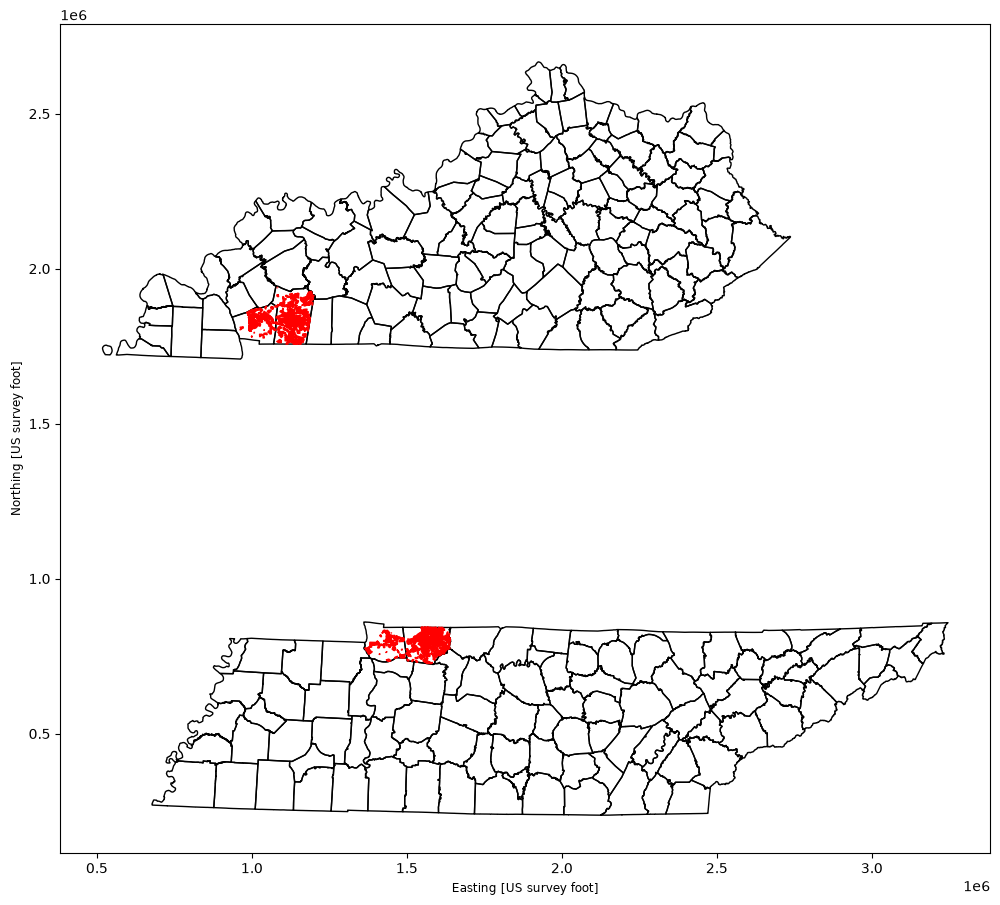

In [94]:
# tn_geo.plot(column = 'EMP', cmap="viridis", legend=True, vmin=tn_geo['EMP'].min(), vmax=tn_geo['EMP'].max(),)

#plot all together just to make sure it's lookin' right
fig, ax = plt.subplots(figsize=(12, 12))

tn_counties_proj.plot(ax=ax,facecolor='none',edgecolor='black',linewidth=1)

ky_counties_proj.plot(ax=ax,facecolor='none',edgecolor='black',linewidth=1)

tn_geo_proj.plot(ax=ax,facecolor='red',edgecolor='red',linewidth=1)

ky_geo_proj.plot(ax=ax,facecolor='red',edgecolor='red',linewidth=1)

plt.show()

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

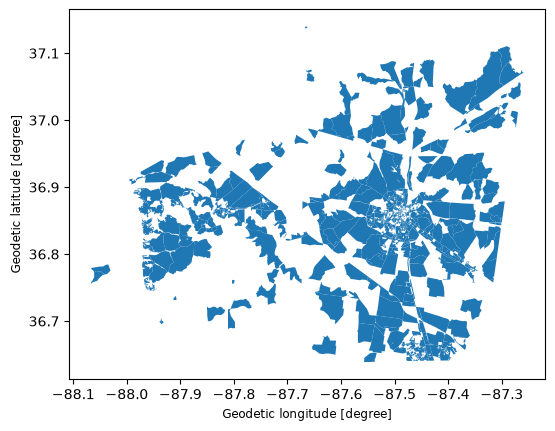

In [95]:
ky_geo.plot()

In [96]:
tn_geo.to_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\2-outputs\2-geospatial\BaseYear.gpkg", layer="TN_EMP_2", driver="GPKG")
ky_geo.to_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\2-outputs\2-geospatial\BaseYear.gpkg", layer="KY_EMP", driver="GPKG")